# 08 — Train, compare and tune the rankers

- Train on `ranker_train.parquet` (features before T1, labels from the validation window); 5-fold `GroupKFold` by user.
- Test on `ranker_test.parquet` (features before T2, labels from the test window). Ranking metrics count **every** product the user liked in the test window, so retrieval misses count against the ranker too.
- The winner is chosen by cross-validated NDCG@10 on the training copy, then confirmed on the test window, so test data never drives a choice.
- Every run is logged to MLflow. View with `mlflow ui --backend-store-uri sqlite:///mlflow.db` from the project root, then open http://localhost:5000.

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import shap
from mlflow.models import infer_signature
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, RandomizedSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

sys.path.insert(0, "../src")
from shoprank.evaluation import evaluate
from shoprank.evaluation.ranking import ranking_metrics, top_k_lists
from shoprank.ranking.models import (
    MODEL_INPUT,
    UserGroupKFold,
    cross_validate_ranker,
    group_sizes,
    make_pipeline,
    predict_score,
)
from shoprank.ranking.preprocess import make_preprocessor
from shoprank.retrieval.baselines import PopularRecommender

ROOT = Path("..").resolve()
PROC, FIG, MODELS = ROOT / "data/processed", ROOT / "reports/figures", ROOT / "models"
T2, K, SEED = pd.Timestamp("2023-01-01"), 10, 42

tr = pd.read_parquet(PROC / "ranker_train.parquet").sort_values("user_id", kind="stable").reset_index(drop=True)
te = pd.read_parquet(PROC / "ranker_test.parquet")
items = pd.read_parquet(PROC / "items.parquet")
val = pd.read_parquet(PROC / "val.parquet")
test = pd.read_parquet(PROC / "test.parquet")
CATALOG = len(items)

truth_train = val[val["liked"] == 1].groupby("user_id")["parent_asin"].agg(set).to_dict()
truth_test = test[test["liked"] == 1].groupby("user_id")["parent_asin"].agg(set).to_dict()
test_users = te["user_id"].unique()
X_tr, y_tr = tr[MODEL_INPUT], tr["label"].to_numpy()
X_te, y_te = te[MODEL_INPUT], te["label"].to_numpy()
print(f"train copy {len(tr):,} rows / {tr['user_id'].nunique():,} users ({y_tr.mean():.2%} positive); "
      f"test copy {len(te):,} rows / {len(test_users):,} users ({y_te.mean():.2%} positive)")

mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")
EXPERIMENT = "shoprank-ranker"
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=(ROOT / "mlruns").as_uri())
mlflow.set_experiment(EXPERIMENT)

train copy 174,135 rows / 1,141 users (0.81% positive); test copy 571,098 rows / 3,719 users (0.22% positive)


2026/10/21 23:29:16 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/21 23:29:16 INFO mlflow.store.db.utils: Updating database tables


<Experiment: artifact_location='file:///Users/karan18/ShopRank/ShopRank/mlruns', creation_time=1792650556691, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792650556691, lifecycle_stage='active', name='shoprank-ranker', tags={}, trace_location=None, workspace='default'>

## Step 6 comparisons first: popularity and retrieval scores alone (test window)

In [2]:
history = pd.concat([pd.read_parquet(PROC / "train.parquet"), val])
seen = history.groupby("user_id")["parent_asin"].agg(set).to_dict()
trending = PopularRecommender(history, days=30, cutoff=T2)

comparisons = {"Trending (last 30 days before T2)": evaluate(trending.recommend, test_users, truth_test, K, seen, CATALOG)}
for col, asc in [("cf_score", False), ("tfidf_score", False), ("emb_score", False), ("pop_rank", True)]:
    comparisons[f"Candidates sorted by {col}"] = ranking_metrics(top_k_lists(te, col, K, ascending=asc), truth_test, K,
                                                                CATALOG, test_users)
comparisons = pd.DataFrame(comparisons).T[[f"recall@{K}", f"ndcg@{K}", f"hit_rate@{K}", f"coverage@{K}"]]
best_retrieval = comparisons.drop(index=comparisons.index[0])[f"ndcg@{K}"].idxmax()
print(f"best retrieval score alone: {best_retrieval}")
comparisons.round(4)

best retrieval score alone: Candidates sorted by pop_rank


,recall@10,ndcg@10,hit_rate@10,coverage@10
Trending (last 30 days before T2),0.0259,0.0171,0.0487,0.0013
Candidates sorted by cf_score,0.0181,0.0109,0.0350,0.7225
Candidates sorted by tfidf_score,0.0176,0.0096,0.0363,0.6460
Candidates sorted by emb_score,0.0141,0.0087,0.0304,0.5762
Candidates sorted by pop_rank,0.0259,0.0171,0.0487,0.0013


## Run helper: CV → refit on the full training copy → test → MLflow

In [3]:
results, fitted = {}, {}

def simple_params(model):
    return {k: v for k, v in model.get_params().items()
            if isinstance(v, (int, float, str, bool, type(None))) and len(str(v)) < 250}

def test_metrics(model):
    s = predict_score(model, X_te)
    out = {"test_roc_auc": roc_auc_score(y_te, s), "test_pr_auc": average_precision_score(y_te, s)}
    if hasattr(model, "predict_proba"):
        out["test_log_loss"] = log_loss(y_te, np.clip(s, 1e-7, 1 - 1e-7))
    rank = ranking_metrics(top_k_lists(te, s, K), truth_test, K, CATALOG, test_users)
    return out | {f"test_{m}": v for m, v in rank.items()}

def run(name, pipe, data=tr, lambdarank=False, extra_params=None):
    t = time.time()
    with mlflow.start_run(run_name=name) as active:
        _, cv = cross_validate_ranker(pipe, data, truth_train, n_splits=5, k=K, lambdarank=lambdarank)
        fit_params = {"model__group": group_sizes(data)} if lambdarank else {}
        model = clone(pipe).fit(data[MODEL_INPUT], data["label"], **fit_params)
        train_ap = average_precision_score(data["label"], predict_score(model, data[MODEL_INPUT]))
        metrics = cv | {"train_ap": train_ap} | test_metrics(model)

        mlflow.log_params({"model_name": name, "train_rows": len(data)} | simple_params(pipe.named_steps["model"])
                          | (extra_params or {}))
        mlflow.log_metrics({k.replace("@", "_at_"): float(v) for k, v in metrics.items()})
        sample = X_te.head(100)
        mlflow.sklearn.log_model(model, name="model", serialization_format="cloudpickle",
                                 signature=infer_signature(sample, predict_score(model, sample)))
        results[name] = metrics | {"seconds": time.time() - t, "run_id": active.info.run_id}
    fitted[name] = model
    print(f"{name:32} cv_ap {cv['cv_ap']:.4f}  cv_ndcg@10 {cv[f'cv_ndcg@{K}']:.4f}  "
          f"test_ndcg@10 {metrics[f'test_ndcg@{K}']:.4f}  ({time.time() - t:.0f}s)")
    return model

## LightGBM: early stopping on a validation slice (20% of training users)

In [4]:
fit_idx, stop_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X_tr, y_tr, tr["user_id"]))
pre = make_preprocessor().fit(X_tr.iloc[fit_idx])
probe = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, random_state=SEED, verbose=-1)
probe.fit(pre.transform(X_tr.iloc[fit_idx]), y_tr[fit_idx],
          eval_set=[(pre.transform(X_tr.iloc[stop_idx]), y_tr[stop_idx])], eval_metric="average_precision",
          callbacks=[lgb.early_stopping(100, first_metric_only=True, verbose=False)])
LGBM_TREES = max(probe.best_iteration_, 50)
print(f"early stopping picked {probe.best_iteration_} trees -> using {LGBM_TREES}")

/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


early stopping picked 200 trees -> using 200


## Step 2 — Train each model

KNN is fit on a ~50K-row sample of whole users (it predicts by brute-force distance to every training row).

In [5]:
rows_per_user = tr.groupby("user_id").size().sample(frac=1, random_state=SEED)
knn_users = rows_per_user.index[rows_per_user.cumsum() <= 50_000]
knn_data = tr[tr["user_id"].isin(knn_users)].reset_index(drop=True)
print(f"KNN sample: {len(knn_data):,} rows, {len(knn_users):,} users")

base_models = {
    "Logistic regression": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Linear SVM (calibrated)": CalibratedClassifierCV(LinearSVC(C=0.1), cv=3),
    "Decision tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "Decision tree (depth 8)": DecisionTreeClassifier(max_depth=8, random_state=SEED),
    "Decision tree (no limit)": DecisionTreeClassifier(max_depth=None, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "LightGBM": lgb.LGBMClassifier(n_estimators=LGBM_TREES, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                   subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
}

run("KNN (50K-row sample)", make_pipeline(KNeighborsClassifier(n_neighbors=100)), data=knn_data)
for name, model in base_models.items():
    run(name, make_pipeline(model))

KNN sample: 49,923 rows, 326 users


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/21 23:29:41 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

KNN (50K-row sample)             cv_ap 0.0241  cv_ndcg@10 0.1014  test_ndcg@10 0.0182  (23s)


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/21 23:29:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

Logistic regression              cv_ap 0.0291  cv_ndcg@10 0.1023  test_ndcg@10 0.0245  (5s)


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/21 23:29:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

Linear SVM (calibrated)          cv_ap 0.0302  cv_ndcg@10 0.1049  test_ndcg@10 0.0250  (6s)


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/21 23:29:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

Decision tree (depth 3)          cv_ap 0.0194  cv_ndcg@10 0.0966  test_ndcg@10 0.0199  (5s)


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/21 23:30:04 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

Decision tree (depth 8)          cv_ap 0.0258  cv_ndcg@10 0.0976  test_ndcg@10 0.0222  (7s)


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/21 23:30:14 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

Decision tree (no limit)         cv_ap 0.0092  cv_ndcg@10 0.0471  test_ndcg@10 0.0075  (10s)


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/21 23:30:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

Random forest                    cv_ap 0.0509  cv_ndcg@10 0.1473  test_ndcg@10 0.0312  (42s)


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/21 23:31:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

LightGBM                         cv_ap 0.0459  cv_ndcg@10 0.1383  test_ndcg@10 0.0271  (11s)


### Overfitting: decision tree depth

In [6]:
trees = [n for n in results if n.startswith("Decision tree")]
pd.DataFrame(results).T.loc[trees, ["train_ap", "cv_ap", f"cv_ndcg@{K}", f"test_ndcg@{K}"]].astype(float).round(4)

,train_ap,cv_ap,cv_ndcg@10,test_ndcg@10
Decision tree (depth 3),0.0226,0.0194,0.0966,0.0199
Decision tree (depth 8),0.1102,0.0258,0.0976,0.0222
Decision tree (no limit),1.0000,0.0092,0.0471,0.0075


## Voting and stacking over the top 3 (by CV NDCG@10)

KNN is left out: it is fit on a sample and would dominate the ensembles' run time. Each member is a full pipeline (own preprocessor), and the outer step is an identity transform, so `user_id` reaches the stacker and its internal CV also splits by user (`UserGroupKFold`).

In [7]:
ranked = pd.DataFrame(results).T.drop(index="KNN (50K-row sample)")[f"cv_ndcg@{K}"].astype(float).sort_values(ascending=False)
top3 = ranked.index[:3].tolist()
print("top 3:", top3)
members = [(n.split(" (")[0].replace(" ", "_").lower(), make_pipeline(clone(base_models[n]))) for n in top3]
identity = FunctionTransformer()

run("Voting (soft, top 3)", Pipeline([("pre", identity), ("model", VotingClassifier(members, voting="soft"))]),
    extra_params={"members": ", ".join(top3)})
run("Stacking (top 3 + LR)", Pipeline([("pre", identity), ("model", StackingClassifier(
        members, final_estimator=LogisticRegression(max_iter=1000), cv=UserGroupKFold(3)))]),
    extra_params={"members": ", ".join(top3), "inner_cv": "UserGroupKFold(3)"})

top 3: ['Random forest', 'LightGBM', 'Linear SVM (calibrated)']


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/21 23:32:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

Voting (soft, top 3)             cv_ap 0.0492  cv_ndcg@10 0.1488  test_ndcg@10 0.0301  (55s)


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/21 23:34:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

Stacking (top 3 + LR)            cv_ap 0.0507  cv_ndcg@10 0.1475  test_ndcg@10 0.0301  (150s)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['n_purchases','avg_rating_given','days_since_last',...,'segment_id', 'store','user_id']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('random_forest', ...), ('lightgbm', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...max_iter=1000)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are 

## Step 4 — Tune the best two single models

RandomizedSearchCV (30 tries, wide ranges) → GridSearchCV (narrow, around the best). Both score with `average_precision` under 3-fold `GroupKFold` by user; the tuned models are then confirmed with CV NDCG@10.

In [8]:
spaces = {
    "LightGBM": {"model__num_leaves": randint(8, 128), "model__learning_rate": loguniform(0.01, 0.2),
                 "model__n_estimators": randint(100, 800), "model__min_child_samples": randint(10, 400),
                 "model__subsample": uniform(0.5, 0.5), "model__colsample_bytree": uniform(0.4, 0.6)},
    "Random forest": {"model__n_estimators": randint(100, 400), "model__max_depth": [None, 8, 12, 16, 24],
                      "model__min_samples_leaf": randint(1, 60), "model__max_features": ["sqrt", 0.3, 0.5]},
    "Logistic regression": {"model__C": loguniform(1e-3, 1e2)},
    "Linear SVM (calibrated)": {"model__estimator__C": loguniform(1e-3, 1e1)},
    "Decision tree (depth 8)": {"model__max_depth": randint(3, 20), "model__min_samples_leaf": randint(1, 300)},
}

def narrow_grid(name, best):
    def around(key, factors, cast=float, lo=None):
        vals = sorted({cast(best[key] * f) for f in factors})
        return [v for v in vals if lo is None or v >= lo]
    if name == "LightGBM":
        return {"model__num_leaves": around("model__num_leaves", [0.75, 1, 1.25], int, 2),
                "model__learning_rate": around("model__learning_rate", [0.7, 1, 1.4]),
                "model__min_child_samples": around("model__min_child_samples", [0.5, 1, 2], int, 1)}
    if name == "Random forest":
        return {"model__min_samples_leaf": around("model__min_samples_leaf", [0.5, 1, 2], int, 1),
                "model__max_features": [best["model__max_features"]],
                "model__max_depth": [best["model__max_depth"]]}
    if name == "Decision tree (depth 8)":
        return {"model__max_depth": around("model__max_depth", [0.8, 1, 1.2], int, 1),
                "model__min_samples_leaf": around("model__min_samples_leaf", [0.5, 1, 2], int, 1)}
    key = next(iter(best))
    return {key: around(key, [1 / 3, 1 / 1.7, 1, 1.7, 3])}

singles = [n for n in ranked.index if n in spaces]
to_tune = singles[:2]
print("tuning:", to_tune)

search_log = {}
for name in to_tune:
    t = time.time()
    base = make_pipeline(clone(base_models[name]))
    rs = RandomizedSearchCV(base, spaces[name], n_iter=30, scoring="average_precision", cv=GroupKFold(3),
                            random_state=SEED, n_jobs=1, refit=False).fit(X_tr, y_tr, groups=tr["user_id"])
    grid = narrow_grid(name, rs.best_params_)
    gs = GridSearchCV(base.set_params(**rs.best_params_), grid, scoring="average_precision", cv=GroupKFold(3),
                      n_jobs=1, refit=False).fit(X_tr, y_tr, groups=tr["user_id"])
    best_params = rs.best_params_ | gs.best_params_
    search_log[name] = {"random_best_ap": rs.best_score_, "grid_best_ap": gs.best_score_, "params": best_params,
                        "seconds": time.time() - t}
    print(f"{name}: random AP {rs.best_score_:.4f} -> grid AP {gs.best_score_:.4f} in {time.time() - t:.0f}s")
    print("   ", {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items()})
    run(f"{name} (tuned)", make_pipeline(clone(base_models[name])).set_params(**best_params),
        extra_params={"search": "random(30) + grid", "search_ap": round(gs.best_score_, 5)})

tuning: ['Random forest', 'LightGBM']


Random forest: random AP 0.0498 -> grid AP 0.0503 in 767s
    {'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 7, 'n_estimators': 206}


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/21 23:47:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

Random forest (tuned)            cv_ap 0.0509  cv_ndcg@10 0.1479  test_ndcg@10 0.0322  (29s)


LightGBM: random AP 0.0500 -> grid AP 0.0523 in 720s
    {'colsample_bytree': np.float64(0.5616), 'learning_rate': 0.0145, 'min_child_samples': 162, 'n_estimators': 473, 'num_leaves': 29, 'subsample': np.float64(0.7594)}


/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/22 00:00:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

LightGBM (tuned)                 cv_ap 0.0559  cv_ndcg@10 0.1517  test_ndcg@10 0.0319  (23s)


## Step 8 (stretch) — LGBMRanker with LambdaRank

Optimizes the order within each user's list directly; trained with one group per user.

In [9]:
lgbm_tuned = search_log.get("LightGBM", {}).get("params", {})
ranker_params = {k: v for k, v in lgbm_tuned.items() if k != "model__n_estimators"}
ranker = make_pipeline(lgb.LGBMRanker(objective="lambdarank", n_estimators=LGBM_TREES, learning_rate=0.05,
                                      num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                      lambdarank_truncation_level=K, random_state=SEED, verbose=-1))
run("LGBMRanker (lambdarank)", ranker.set_params(**ranker_params), lambdarank=True)

/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/22 00:00:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exec

LGBMRanker (lambdarank)          cv_ap 0.0523  cv_ndcg@10 0.1433  test_ndcg@10 0.0299  (12s)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['n_purchases','avg_rating_given','days_since_last',...,'segment_id', 'store','user_id']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('segment', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This 

## Results — winner by CV NDCG@10, then the test window

In [10]:
table = pd.DataFrame(results).T
cols = ["cv_ap", f"cv_ndcg@{K}", "train_ap", "test_roc_auc", "test_pr_auc", "test_log_loss",
        f"test_recall@{K}", f"test_ndcg@{K}", f"test_coverage@{K}", "seconds"]
table = table[cols].astype(float).sort_values(f"cv_ndcg@{K}", ascending=False)
WINNER = table.index[0]
print(f"winner by CV NDCG@10: {WINNER}   (best on test: {table[f'test_ndcg@{K}'].idxmax()})")
table.round(4)

winner by CV NDCG@10: LightGBM (tuned)   (best on test: Random forest (tuned))


,cv_ap,cv_ndcg@10,train_ap,test_roc_auc,test_pr_auc,test_log_loss,test_recall@10,test_ndcg@10,test_coverage@10,seconds
LightGBM (tuned),0.0559,0.1517,0.2455,0.7790,0.0094,0.0167,0.0482,0.0319,0.2602,22.5838
"Voting (soft, top 3)",0.0492,0.1488,0.6577,0.7672,0.0087,0.0183,0.0463,0.0301,0.2353,54.7636
Random forest (tuned),0.0509,0.1479,0.4512,0.7619,0.0108,0.0184,0.0490,0.0322,0.2490,28.6893
Stacking (top 3 + LR),0.0507,0.1475,0.7207,0.7677,0.0088,0.0183,0.0465,0.0301,0.2349,149.6223
Random forest,0.0509,0.1473,0.8401,0.7504,0.0097,0.0202,0.0469,0.0312,0.2364,42.1172
LGBMRanker (lambdarank),0.0523,0.1433,0.1745,0.7636,0.0086,NaN,0.0473,0.0299,0.2577,12.3109
LightGBM,0.0459,0.1383,0.5847,0.7682,0.0077,0.0176,0.0448,0.0271,0.2670,10.6130
Linear SVM (calibrated),0.0302,0.1049,0.0305,0.7249,0.0069,0.0179,0.0415,0.0250,0.2344,6.4716
Logistic regression,0.0291,0.1023,0.0293,0.7316,0.0068,0.5890,0.0406,0.0245,0.2071,5.0058
KNN (50K-row sample),0.0241,0.1014,0.0494,0.6400,0.0041,0.0254,0.0308,0.0182,0.3502,22.8672


In [11]:
w = table.loc[WINNER]
trend_ndcg = comparisons.iloc[0][f"ndcg@{K}"]
retr_ndcg = comparisons.loc[best_retrieval, f"ndcg@{K}"]
print(f"test NDCG@10: {WINNER} {w[f'test_ndcg@{K}']:.4f}  vs trending {trend_ndcg:.4f} "
      f"({w[f'test_ndcg@{K}'] / trend_ndcg - 1:+.0%})  vs {best_retrieval} {retr_ndcg:.4f} ({w[f'test_ndcg@{K}'] / retr_ndcg - 1:+.0%})")
assert w[f"test_ndcg@{K}"] > trend_ndcg and w[f"test_ndcg@{K}"] > retr_ndcg

test NDCG@10: LightGBM (tuned) 0.0319  vs trending 0.0171 (+87%)  vs Candidates sorted by pop_rank 0.0171 (+87%)


## Step 7 — Explain the winner with SHAP

TreeExplainer on the winner's tree model (for an ensemble, its LightGBM member), on 5,000 test rows after preprocessing.

/Users/karan18/ShopRank/ShopRank/.venv/lib/python3.14/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


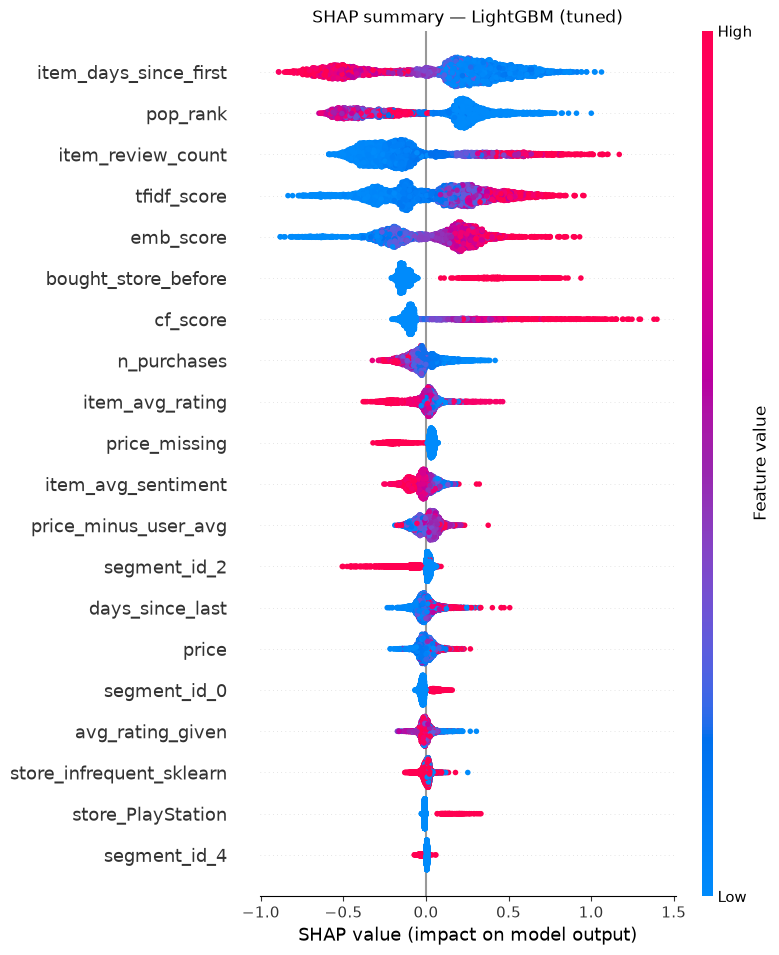

,mean |SHAP|
item_days_since_first,0.3705
pop_rank,0.3193
item_review_count,0.2796
tfidf_score,0.2667
emb_score,0.2317
bought_store_before,0.1716
cf_score,0.1651
n_purchases,0.0796
item_avg_rating,0.0626
price_missing,0.0588


In [12]:
winner = fitted[WINNER]
est, pre_step, explained = winner.named_steps["model"], winner.named_steps["pre"], WINNER
if isinstance(est, (VotingClassifier, StackingClassifier)):
    order = ["lightgbm", "random_forest", "decision_tree"]
    name = min((n for n in est.named_estimators_ if n in order), key=order.index)
    member = est.named_estimators_[name]
    est, pre_step, explained = member.named_steps["model"], member.named_steps["pre"], f"{WINNER} → {name} member"

sample = X_te.sample(5000, random_state=SEED)
Xs = pre_step.transform(sample)
names = [n.split("__", 1)[1] for n in pre_step.get_feature_names_out()]
try:
    sv = shap.TreeExplainer(est).shap_values(Xs)
except Exception:
    sv = shap.LinearExplainer(est, Xs).shap_values(Xs)
sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if np.ndim(sv) == 3 else sv)

shap.summary_plot(sv, Xs, feature_names=names, max_display=20, show=False)
plt.title(f"SHAP summary — {explained}")
plt.savefig(FIG / "shap_summary.png", dpi=120, bbox_inches="tight")
plt.show()

importance = pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False)
importance.head(15).round(4).to_frame("mean |SHAP|")

## Step 9 — Register the winner as `shoprank-ranker`

In [13]:
run_id = results[WINNER]["run_id"]
with mlflow.start_run(run_id=run_id):
    mlflow.log_artifact(str(FIG / "shap_summary.png"))
    mlflow.set_tag("winner", "true")
version = mlflow.register_model(f"runs:/{run_id}/model", "shoprank-ranker")
joblib.dump(winner, MODELS / "ranker.joblib")
print(f"registered shoprank-ranker version {version.version} from run {run_id} ({WINNER}); also saved models/ranker.joblib")
print(f"runs logged in experiment '{EXPERIMENT}': {len(mlflow.search_runs(experiment_names=[EXPERIMENT]))}")

Successfully registered model 'shoprank-ranker'.
2026/10/22 00:00:25 WARNING mlflow.tracking._model_registry.fluent: Run with id cd3a74a01f6e4a5c8d5b3caa98839268 has no artifacts at artifact path 'model', registering model based on models:/m-7d857b72e5a74e699b9219b79440f9b1 instead


registered shoprank-ranker version 1 from run cd3a74a01f6e4a5c8d5b3caa98839268 (LightGBM (tuned)); also saved models/ranker.joblib
runs logged in experiment 'shoprank-ranker': 13


Created version '1' of model 'shoprank-ranker'.
